# 03 — Asymmetric setup for a left-turn-only car: left-side weight, wedge and LLTD

A NASCAR oval car only turns left, so the setup is **intentionally asymmetric**: left-side weight bias, cross weight ("wedge"), asymmetric springs, camber, tyre pressures and (historically) stagger. This notebook uses a steady-state four-wheel model on a banked turn to show *why* each lever works. The mechanism is the same throughout: **tyre load sensitivity**.

**Model**
* Static wheel loads from: front %, left %, cross % $=(RF+LR)/W$
* On the bank: static loads scale with $a_n/g$, aero downforce is split by aero balance
* Lateral load transfer $\Delta F = m\,a_{y'}\,h/t$, split front/rear by LLTD (roll-stiffness distribution)
* Tyre: $F_{y,max} = \mu_0 (F_z/F_{z0})^{-k}\,F_z$, a concave function, so unequal loads on an axle lose grip
* Axle demand from moment balance: front $= F_{y}\,b/L$, rear $= F_{y}\,a/L$
* The axle that saturates first sets the limit **and** the balance: front first is *tight* (push), rear first is *loose*.

Linear springs mean a diagonal (wedge) preload stays roughly constant as the car rolls, so it is treated as additive.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
RHO, G, MPH = 1.18, 9.81, 2.23694

BASE = dict(m=1600., L=2.794, front=0.52, left=0.50, cross=0.50, h=0.40, t=1.63,
            LLTD=0.50, ClA=1.6, aero_front=0.54, mu0=1.0, k_ls=0.15, Fz0=4000.,
            R=215., bank=np.deg2rad(24))

def static_loads(p):
    W = p['m']*G; f, l, x = p['front'], p['left'], p['cross']
    LF = (f + l - x)*W/2; RF = f*W - LF; LR = l*W - LF; RR = W - LF - RF - LR
    return np.array([LF, RF, LR, RR])

def wheel_loads(p, v):
    th, R = p['bank'], p['R']
    an  = G*np.cos(th) + v**2/R*np.sin(th)
    ayp = v**2/R*np.cos(th) - G*np.sin(th)
    Fz = static_loads(p)*an/G
    D = 0.5*RHO*p['ClA']*v**2
    Fz += np.array([p['aero_front']/2]*2 + [(1-p['aero_front'])/2]*2)*D
    dF = p['m']*ayp*p['h']/p['t']                       # total lateral load transfer
    dFf, dFr = p['LLTD']*dF, (1-p['LLTD'])*dF
    Fz += np.array([-dFf, +dFf, -dFr, +dFr])            # left turn -> load goes right
    return Fz, p['m']*ayp

def tyre_cap(p, Fz):
    Fz = np.clip(Fz, 1.0, None)
    return p['mu0']*(Fz/p['Fz0'])**(-p['k_ls'])*Fz

def utilisation(p, v):
    Fz, Fy = wheel_loads(p, v)
    cap = tyre_cap(p, Fz)
    a = (1-p['front'])*p['L']; b = p['front']*p['L']    # a: CG->front axle, b: CG->rear axle
    uf = Fy*(b/p['L'])/(cap[0]+cap[1])
    ur = Fy*(a/p['L'])/(cap[2]+cap[3])
    return uf, ur, Fz

def vmax(p):
    lo, hi = 20., 130.
    for _ in range(50):
        v = 0.5*(lo+hi); uf, ur, _ = utilisation(p, v)
        lo, hi = (v, hi) if max(uf, ur) <= 1 else (lo, v)
    uf, ur, Fz = utilisation(p, lo)
    return lo, uf - ur, Fz      # balance > 0 : front saturates first = TIGHT

v, bal, Fz = vmax(BASE)
print(f'Baseline: v_max = {v*MPH:.1f} mph, balance index (u_f - u_r) = {bal:+.3f}')
print('Wheel loads at limit [N]  LF {:.0f}  RF {:.0f}  LR {:.0f}  RR {:.0f}'.format(*Fz))

Baseline: v_max = 168.3 mph, balance index (u_f - u_r) = -0.000
Wheel loads at limit [N]  LF 5686  RF 13558  LR 4844  RR 12715


## 1. Left-side weight
Moving static weight to the inside pre-compensates the load transfer to the right. The outside and inside tyres end up closer to equal at the limit, and with a concave tyre curve that means more total grip.

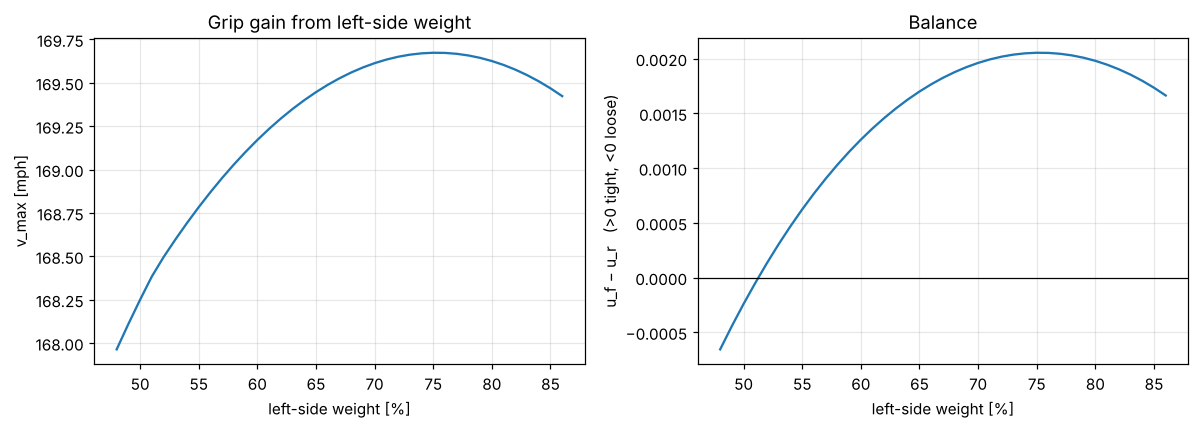

optimum left % in this model ≈ 75.0 %  (gain 1.6 mph ≈ 0.9 % vs 49 %)


In [2]:
lefts = np.linspace(0.48, 0.86, 39)
vv, bb = [], []
for l in lefts:
    p = dict(BASE, left=l); v, b, _ = vmax(p); vv.append(v*MPH); bb.append(b)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(lefts*100, vv); ax[0].set(xlabel='left-side weight [%]', ylabel='v_max [mph]', title='Grip gain from left-side weight')
ax[1].plot(lefts*100, bb); ax[1].axhline(0, c='k', lw=0.8)
ax[1].set(xlabel='left-side weight [%]', ylabel='u_f − u_r   (>0 tight, <0 loose)', title='Balance')
plt.tight_layout(); plt.show()
print(f'optimum left % in this model ≈ {lefts[np.argmax(vv)]*100:.1f} %  (gain {max(vv)-vv[1]:.1f} mph ≈ {(max(vv)/vv[1]-1)*100:.1f} % vs 49 %)')

The optimum would sit far to the left if allowed. That is exactly why sanctioning bodies regulate it. Historically NASCAR set a **maximum** left-side weight percentage (check the current rulebook for the Next Gen value). Teams then run at the limit, and fine-tune the balance with the remaining levers below.

## 2. Cross weight ("wedge") and LLTD as balance tools
Wedge > 50 % loads the RF–LR diagonal. In a left turn this **unequalises the front** (RF is already heavy) and **equalises the rear** (LR gains, RR loses). The result: front grip down, rear grip up, so the car gets **tighter**. More front roll stiffness (LLTD) does the same through the transfer itself.

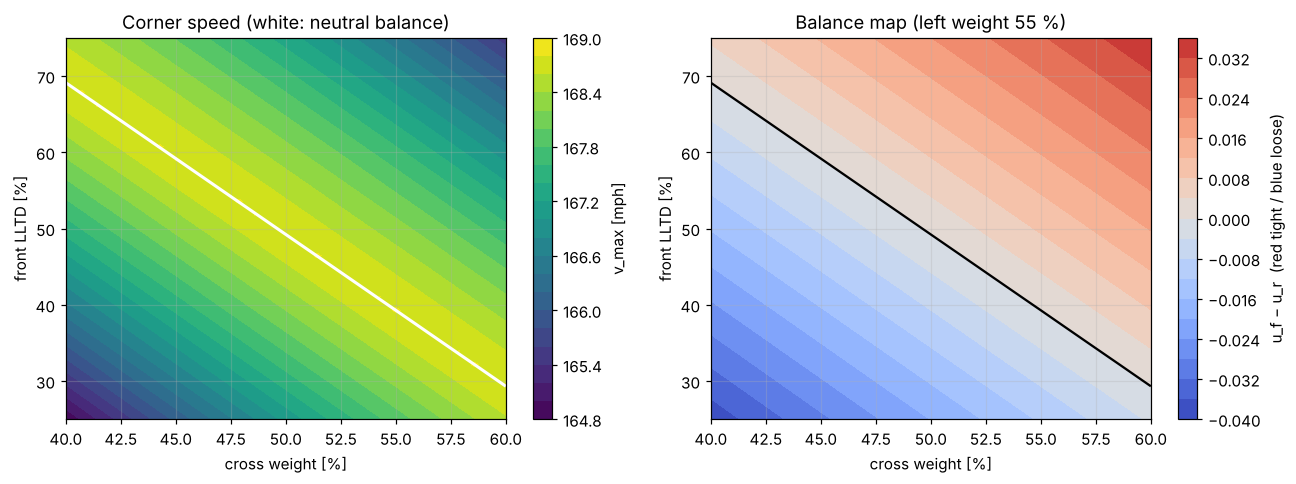

max v = 168.8 mph at cross 55.0 %, LLTD 39.3 %, balance +0.000


In [3]:
cross = np.linspace(0.40, 0.60, 29); lltd = np.linspace(0.25, 0.75, 29)
V = np.zeros((len(lltd), len(cross))); B = np.zeros_like(V)
for i, q in enumerate(lltd):
    for j, x in enumerate(cross):
        v, b, _ = vmax(dict(BASE, left=0.55, cross=x, LLTD=q)); V[i, j] = v*MPH; B[i, j] = b
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
c0 = ax[0].contourf(cross*100, lltd*100, V, 20, cmap='viridis'); plt.colorbar(c0, ax=ax[0], label='v_max [mph]')
ax[0].contour(cross*100, lltd*100, B, levels=[0], colors='w', linewidths=2)
ax[0].set(xlabel='cross weight [%]', ylabel='front LLTD [%]', title='Corner speed (white: neutral balance)')
lim = np.abs(B).max()
c1 = ax[1].contourf(cross*100, lltd*100, B, 21, cmap='coolwarm', vmin=-lim, vmax=lim)
plt.colorbar(c1, ax=ax[1], label='u_f − u_r  (red tight / blue loose)')
ax[1].contour(cross*100, lltd*100, B, levels=[0], colors='k', linewidths=1.5)
ax[1].set(xlabel='cross weight [%]', ylabel='front LLTD [%]', title='Balance map (left weight 55 %)')
plt.tight_layout(); plt.show()
i, j = np.unravel_index(np.argmax(V), V.shape)
print(f'max v = {V[i,j]:.1f} mph at cross {cross[j]*100:.1f} %, LLTD {lltd[i]*100:.1f} %, balance {B[i,j]:+.3f}')

**Observations**
* Maximum speed lies on (or very close to) the **neutral-balance line**. In steady state, a perfectly balanced car is the fastest car. The *ridge* is what matters: many cross/LLTD combinations are equally fast in steady state.
* Teams choose a point on that ridge from **transient** needs: *tight in, loose off* is a classic complaint because entry (braking, decreasing $a_x$ to the rear) and exit (throttle, rear driven) shift the balance in opposite directions. Wedge also influences how the car behaves when the throttle loads the LR (diagonal coupling via the chassis), which is why crew chiefs traditionally made **wedge (and, on the solid axle, track-bar) adjustments during pit stops**. The track bar disappeared with the Next Gen IRS. Check the current rulebook for which in-race adjustments remain.
* Real cars add more asymmetric levers: **camber** (large negative RF, positive LF), **tyre pressures** (cold pressures change spring rate and contact patch), **asymmetric spring/bump-stop rates**. On the Gen-6 solid axle with a locked differential, **stagger** (larger right-rear circumference) produced a yaw moment that "turned" the car. The Next Gen transaxle uses a ramp-and-plate differential, which changes how much stagger and diff settings contribute.

## 3. The banking interaction
Same car, same setup, different banking. A setup that is neutral at 24° is not neutral at 12°, because the ratio of lateral transfer to normal load changes (notebook 01). This is one reason no single "oval setup" exists and why simulation is used to transfer knowledge between tracks.

In [4]:
p0 = dict(BASE, left=0.55)
# find the neutral cross weight at 24°
xs = np.linspace(0.25, 0.75, 201)
bal24 = [vmax(dict(p0, cross=x))[1] for x in xs]
x_neutral = xs[np.argmin(np.abs(bal24))]
print(f'neutral cross weight at 24° banking: {x_neutral*100:.1f} %')
for bank, R in [(31, 306), (24, 215), (12, 65)]:
    p = dict(p0, cross=x_neutral, bank=np.deg2rad(bank), R=R)
    v, b, _ = vmax(p)
    bals = [vmax(dict(p, cross=x))[1] for x in xs]
    print(f'θ={bank:2d}°, R={R:3d} m: v={v*MPH:6.1f} mph, balance with same wedge {b:+.3f} '
          f'→ neutral wedge here ≈ {xs[np.argmin(np.abs(bals))]*100:.1f} %')

neutral cross weight at 24° banking: 49.5 %


θ=31°, R=306 m: v= 250.5 mph, balance with same wedge -0.004 → neutral wedge here ≈ 52.2 %


θ=24°, R=215 m: v= 168.8 mph, balance with same wedge -0.000 → neutral wedge here ≈ 49.5 %


θ=12°, R= 65 m: v=  69.7 mph, balance with same wedge +0.007 → neutral wedge here ≈ 46.2 %


### Extensions worth doing (MBS mindset)
1. Replace the scalar LLTD with real **roll and warp stiffness**, including chassis torsional compliance. The diagonal (warp) mode is what wedge actually acts on.
2. Add **bump stops / travel limiters**: under 2–3 g vertical the car runs on the stops, the effective roll stiffness becomes nonlinear and ride height (and so the aero map) is set by the stops.
3. Swap the power-law tyre for **Magic Formula** with camber, pressure and load sensitivity. An asymmetric camber/pressure study then becomes possible.
4. Couple with notebook 02's QSS loop to get **lap-time sensitivity to wedge**.